<a href="https://colab.research.google.com/github/icaaja19/praktikum-pcd/blob/main/praktikum_PCD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

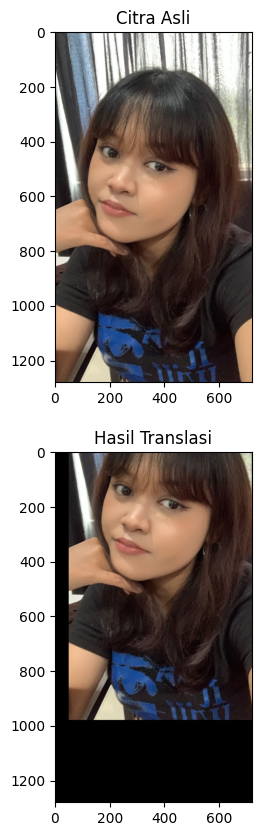

In [ ]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def Translasi(image, shiftX, shiftY):
    imgTranslasi = np.roll(image, shift=shiftY, axis=0)  # Geser vertikal
    imgTranslasi = np.roll(imgTranslasi, shift=shiftX, axis=1)  # Geser horizontal

    # Mengisi bagian yang kosong dengan warna hitam (0)
    if shiftY > 0:
        imgTranslasi[:shiftY, :] = 0  # Bagian atas jika geser ke bawah
    elif shiftY < 0:
        imgTranslasi[shiftY:, :] = 0  # Bagian bawah jika geser ke atas

    if shiftX > 0:
        imgTranslasi[:, :shiftX] = 0  # Bagian kiri jika geser ke kanan
    elif shiftX < 0:
        imgTranslasi[:, shiftX:] = 0  # Bagian kanan jika geser ke kiri

    return imgTranslasi

# Ganti path sesuai tempat penyimpanan gambar di komputer Anda
image = img.imread("/content/WhatsApp Image 2026-10-30 at 12.26.09.jpeg")

imgResult = Translasi(image, shiftX=50, shiftY=-300)

plt.figure(figsize=(10, 10))
plt.subplot(2, 1, 1)
plt.imshow(image)
plt.title("Citra Asli")

plt.subplot(2, 1, 2)
plt.imshow(imgResult)
plt.title("Hasil Translasi")

plt.show()

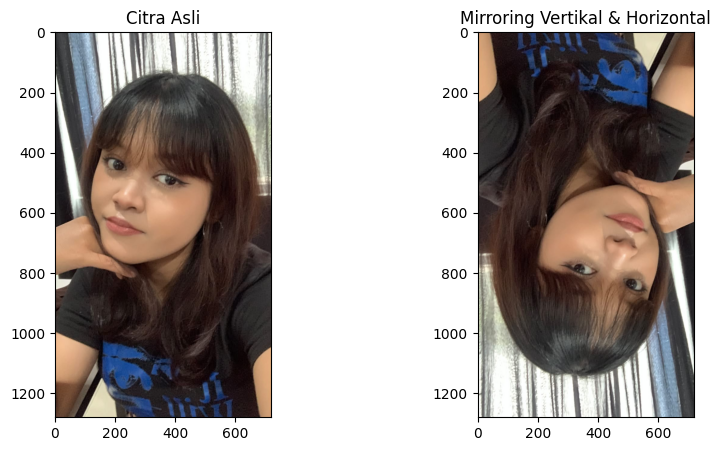

In [ ]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

path = '/content/WhatsApp Image 2026-10-30 at 12.26.09.jpeg'
image = img.imread(path)

height, width = image.shape[:2]
combined_mirror = np.zeros_like(image)

# Loop untuk membalik horizontal sekaligus vertikal
for y in range(height):
    for x in range(width):
        combined_mirror[y, x] = image[height - 1 - y, width - 1 - x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Citra Asli")

plt.subplot(1, 2, 2)
plt.imshow(combined_mirror)
plt.title("Mirroring Vertikal & Horizontal")

plt.show()

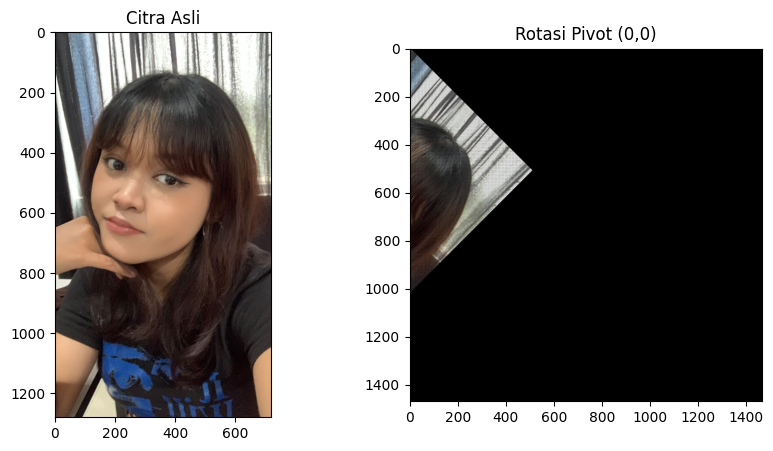

In [ ]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImagePivotTopLeft(image, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]

    # Hitung dimensi maksimum kanvas agar hasil rotasi tidak terpotong
    max_dim = int(np.sqrt(height**2 + width**2))
    outputImage = np.zeros((max_dim, max_dim, 3), dtype=image.dtype)

    for y in range(height):
        for x in range(width):
            # Rotasi berpatokan pada pivot (0,0) pojok kiri atas
            newX = int(cos_deg * x - sin_deg * y)
            newY = int(sin_deg * x + cos_deg * y)

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y, x]

    return outputImage

image = img.imread('/content/WhatsApp Image 2026-10-30 at 12.26.09.jpeg')
rotated_image = rotateImagePivotTopLeft(image, 45)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Citra Asli")

plt.subplot(1, 2, 2)
plt.imshow(rotated_image)
plt.title("Rotasi Pivot (0,0)")

plt.show()

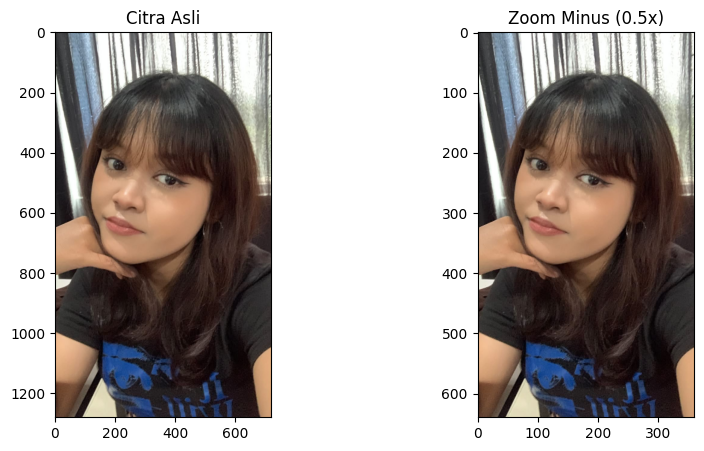

In [ ]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt

def zoomMinus(image, factor):
    height, width = image.shape[:2]

    # Menghitung ukuran citra baru yang lebih kecil
    new_height = int(height * factor)
    new_width = int(width * factor)

    imgZoom = np.zeros((new_height, new_width, 3), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):
            ori_y = int(y / factor)
            ori_x = int(x / factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom

image = img.imread('/content/WhatsApp Image 2026-10-30 at 12.26.09.jpeg')
skala = 0.5  # Memperkecil 50%

imgZoom = zoomMinus(image, skala)
img.imwrite("zoom_minus_result.jpg", imgZoom)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Citra Asli")

plt.subplot(1, 2, 2)
plt.imshow(imgZoom)
plt.title("Zoom Minus (0.5x)")

plt.show()